# Nested rings
Enter a value (LEN). The notebook builds the ladder LEN, LEN//2, ..., 1 as solid nested rings. A ring of LEN n is n slices per word, thickness n, touching the ring inside it.
Word order is a hook: `ORDER_OVERRIDE[L] = [...]` replaces the default (counting order) for that ring.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge
import math, random

VALUE = 8                 # <- enter a value here (or use the box in the last cell)
ORDER_OVERRIDE = {}       # e.g. {3: ["000","010","110","011","101","111"]}  (any ring, explicit word order)
DRAW_MAX = 8              # largest ring that gets drawn (ring 8 = 2048 slices)
BUILD_MAX = 12            # largest ring built as explicit data

In [2]:
def chain(v):
    out = []
    while v >= 1: out.append(v); v //= 2
    return out[::-1]                      # smallest (core) first

def words(L):
    if L in ORDER_OVERRIDE: return list(ORDER_OVERRIDE[L])
    return [format(w, f"0{L}b") for w in range(1 << L)]      # counting order, clockwise from the top

def ring_string(L): return "".join(words(L))               # every slice, clockwise

def build(v):
    return {L: ring_string(L) for L in chain(v) if L <= BUILD_MAX}

def check_len2():
    cyc = words(2); i = cyc.index("11")
    return cyc[i:] + cyc[:i]                                # should read 11 00 01 10

In [3]:
TEAL, GRAY = "#5DCAA5", "#EDEDED"

def draw(v):
    rings = build(v); ls = [L for L in chain(v) if L in rings and L <= DRAW_MAX]
    fig, ax = plt.subplots(figsize=(8, 8)); r0 = 0
    for L in chain(v):
        r1 = r0 + L
        if L in ls:
            s = rings[L]; n = len(s); span = 360 / n
            for i, ch in enumerate(s):
                a0, a1 = i * span, (i + 1) * span
                ax.add_patch(Wedge((0, 0), r1, 90 - a1, 90 - a0, width=L, facecolor=TEAL if ch == "1" else GRAY,
                                   edgecolor=(TEAL if ch == "1" else GRAY) if n > 128 else "#555", linewidth=0.3 if n > 128 else 0.6))
                if n <= 64:
                    m = math.radians(90 - (a0 + a1) / 2); rm = (r0 + r1) / 2
                    ax.text(rm * math.cos(m), rm * math.sin(m), ch, ha="center", va="center", fontsize=8)
            w = words(L); gs = 360 / len(w)
            for j in range(len(w)):
                ax.add_patch(Wedge((0, 0), r1, 90 - (j + 1) * gs, 90 - j * gs, width=L, fill=False,
                                   edgecolor="#222", linewidth=1.6 if len(w) <= 64 else 0.8))
        r0 = r1
    R = sum(chain(v)); ax.set_xlim(-R - 1, R + 1); ax.set_ylim(-R - 1, R + 1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"Rings {chain(v)} (drawn: {ls}); teal = 1, gray = 0; slices run clockwise from the top")
    return fig

In [4]:
# route: same angle, next ring in. The entry never chooses it. Works for any ring size (exact integers).
def size(L): return L * (1 << L)
def bit(L, o):
    w, k = divmod(o % size(L), L); return (w >> (L - 1 - k)) & 1
def window(L, o):
    v = 0
    for i in range(L): v = (v << 1) | bit(L, o + i)
    return v
def fall(L, o): return (o * size(L // 2)) // size(L)
def trace(L, o):
    path = []
    while True:
        path.append((L, o, window(L, o)))
        if L == 1: return path
        o, L = fall(L, o), L // 2
def show_trace(v, entry=None):
    o = entry if entry is not None else random.randrange(size(v))
    print("entry slice", o)
    for L, off, w in trace(v, o): print(f"  ring {L:3d}  offset {off}  reads {w:0{L}b}")

In [5]:
# Does the default ordering reproduce your LEN 2 order (11 -> 00 -> 01 -> 10, read as a circle)?
print("LEN 2 as a circle starting at 11:", " -> ".join(check_len2()))
print("LEN 3 as built:", " ".join(words(3)))

LEN 2 as a circle starting at 11: 11 -> 00 -> 01 -> 10
LEN 3 as built: 000 001 010 011 100 101 110 111


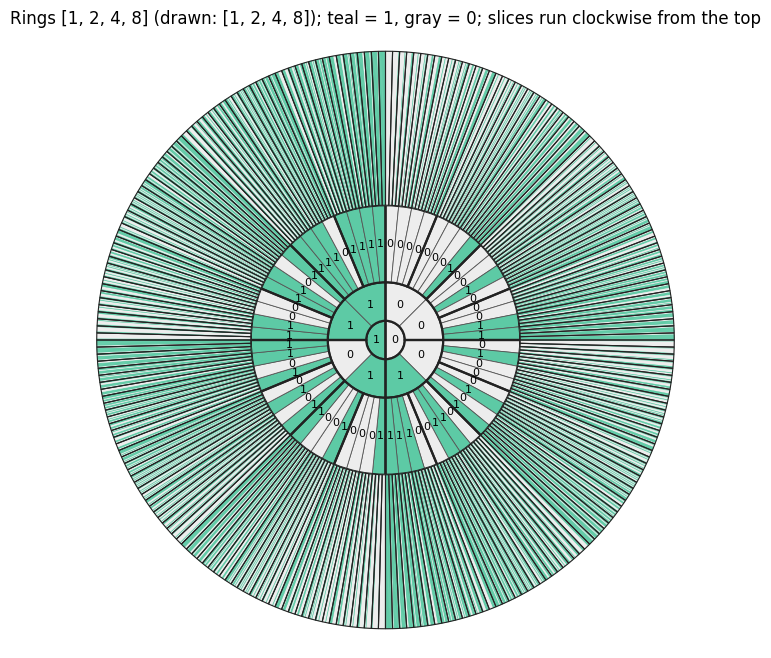

entry slice 268
  ring   8  offset 268  reads 00010010
  ring   4  offset 8  reads 0010
  ring   2  offset 1  reads 00
  ring   1  offset 0  reads 0


In [6]:
fig = draw(VALUE); plt.show()
show_trace(VALUE)

In [7]:
# Optional: a box to enter the value (needs ipywidgets). Otherwise just change VALUE above and re-run.
try:
    import ipywidgets as W
    from IPython.display import clear_output, display
    box = W.BoundedIntText(value=VALUE, min=1, max=64, description="LEN:")
    out = W.Output()
    def go(change=None):
        with out:
            clear_output(wait=True); draw(box.value); plt.show(); show_trace(box.value)
    box.observe(go, names="value"); display(box, out); go()
except ImportError:
    print("ipywidgets not installed: edit VALUE and re-run the cell above.")

BoundedIntText(value=8, description='LEN:', max=64, min=1)

Output()